# A/B-тест формы оплаты ЖКХ
**Автор:** Волков Владимир Алексеевич. **Период эксперимента:** 1–30 апреля 2024 года.

**Цель:** оценить изменение конверсии из открытия формы в успешную оплату и дать рекомендацию о запуске.
**Принимается допущение**: A — старая форма, B — новая.

## Как запустить
Установите зависимости из `requirements.txt`, откройте этот ноутбук в Jupyter/VS Code/colab и выполните ячейки по порядку.
По умолчанию используется `data.xlsx` рядом с ноутбуком. Для другого расположения измените `INPUT_FILE` ниже.
Готовые выводы и графики уже сохранены в ноутбуке; для их просмотра запуск не требуется.

## План и метрики
Основная метрика — число успешных попыток / число открытых форм (CR 1→4). Повторные попытки сохраняются.
Рандомизация выполнена по пользователям, поэтому стандартная ошибка и bootstrap учитывают пользователей как независимые кластеры.
Дополнительная метрика — доля пользователей, открывавших форму и успешно оплативших хотя бы один раз за период.
Она отвечает на другой вопрос и не заменяет основную метрику.
Используем двустороннюю проверку, α = 0,05. Основной вывод делаем по CR 1→4; этапы и сегменты изучаем описательно.
Порог практической полезности в задании отсутствует, поэтому окупаемость внедрения не утверждаем.


In [ ]:
from pathlib import Path
import sys
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 30)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 130})
COLORS = {'A': '#546A80', 'B': '#008577'}
INPUT_FILE = Path('data.xlsx')
if not INPUT_FILE.exists():
    candidates = [p for folder in [Path('.'), Path('upload'), Path('../../upload')]
                  for p in folder.glob('*.xlsx') if 'dannye-dlia-keisa' in p.name]
    if len(candidates) != 1:
        raise FileNotFoundError('Положите data.xlsx рядом с ноутбуком или укажите путь в INPUT_FILE.')
    INPUT_FILE = candidates[0]

users_raw = pd.read_excel(INPUT_FILE, sheet_name='Пользователи')
payments_raw = pd.read_excel(INPUT_FILE, sheet_name='Платежи')
STEPS = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']
START, END = pd.Timestamp('2024-04-01'), pd.Timestamp('2024-05-01')
print('Python:', platform.python_version())
print('pandas:', pd.__version__, '| numpy:', np.__version__, '| scipy:', scipy.__version__)
print('SHA256 источника:', hashlib.sha256(INPUT_FILE.read_bytes()).hexdigest())
print('Пользователи:', users_raw.shape, '| Попытки:', payments_raw.shape)
print('\nПоля пользователей:', ', '.join(users_raw.columns))
print('Поля платежей:', ', '.join(payments_raw.columns))
print('\nПервые 3 попытки:\n', payments_raw.head(3).to_string(index=False))


Python: 3.12.14
pandas: 2.2.3 | numpy: 2.3.5 | scipy: 1.17.0
SHA256 источника: f1e560b834c87e72a494f1413185104c817b3d6e4d4106afed1e5dfd1afb282b
Пользователи: (1504, 5) | Попытки: (2661, 7)

Поля пользователей: user_id, group, age, city, device_type
Поля платежей: payment_id, user_id, group, step1_opened, step2_entered, step3_confirmed, step4_success

Первые 3 попытки:
  payment_id  user_id group        step1_opened       step2_entered step3_confirmed step4_success
       5001   1001.0     A 2024-04-16 06:06:00 2024-04-16 06:10:00             NaT           NaT
       5002   1002.0     A 2024-04-12 07:38:00 2024-04-12 07:41:00             NaT           NaT
       5003   1003.0     A 2024-04-26 20:03:00 2024-04-26 20:07:00             NaT           NaT


## 1. Качество данных и правила обработки
Правила задаём до сравнения конверсий. Пустой следующий шаг означает незавершённую попытку, а не автоматически ошибочную запись.
Проверяем ключи, пропуски, принадлежность группе, период, полноту цепочки и хронологию событий.

* Возраст вне [0; 120] заменяем пропуском; это не основание исключать валидные платежи.
* Пропущенный город обозначаем как «Не указан».
* Пользователь без группы не участвует в сравнении A/B. Пользователи без открытия формы не входят в знаменатель условной CR 1→4.
* Платёж без user_id исключаем: кластер и участника эксперимента установить невозможно.
* При конфликте группы между листами исключаем **все попытки соответствующего пользователя** из основного анализа: нельзя установить, какую форму он действительно видел.
  В анализе чувствительности проверим альтернативные решения.
* Явно некорректные цепочки/даты исключаем, если они есть. Валидные необычные значения и повторные попытки не удаляем.


In [ ]:
users = users_raw.copy()
payments = payments_raw.copy()
for s in STEPS:
    payments[s] = pd.to_datetime(payments[s], errors='coerce')

assert not users['user_id'].duplicated().any(), 'Нужно отдельно разрешить дубликаты user_id'
assert not payments['payment_id'].duplicated().any(), 'Нужно отдельно разрешить дубликаты payment_id'
bad_age = ~users['age'].between(0, 120)
users.loc[bad_age, 'age'] = np.nan
users['city'] = users['city'].fillna('Не указан')
merged = payments.merge(users.rename(columns={'group': 'user_group'}), on='user_id',
                        how='left', validate='many_to_one', indicator=True)
missing_id = merged['user_id'].isna()
unknown_user = merged['_merge'].ne('both') & ~missing_id
invalid_group = ~merged['user_group'].isin(['A', 'B']) & ~missing_id & ~unknown_user
mismatch = merged['user_group'].isin(['A', 'B']) & merged['group'].ne(merged['user_group'])
conflict_ids = merged.loc[mismatch, 'user_id'].unique()
conflict_user = merged['user_id'].isin(conflict_ids)
outside = pd.Series(False, index=merged.index)
bad_sequence = pd.Series(False, index=merged.index)
for s in STEPS:
    outside |= merged[s].notna() & ~merged[s].between(START, END, inclusive='left')
for prev, nxt in zip(STEPS[:-1], STEPS[1:]):
    bad_sequence |= merged[nxt].notna() & (merged[prev].isna() | (merged[nxt] < merged[prev]))
missing_open = merged['step1_opened'].isna()

audit = pd.DataFrame([
    ('Строк пользователей', len(users)),
    ('Строк попыток', len(payments)),
    ('Дубликаты строк пользователей', users_raw.duplicated().sum()),
    ('Дубликаты строк платежей', payments_raw.duplicated().sum()),
    ('Пользователи без user_id', users['user_id'].isna().sum()),
    ('Пользователи без корректной группы', (~users['group'].isin(['A', 'B'])).sum()),
    ('Возраст вне [0; 120]', bad_age.sum()),
    ('Пропущенный город', users_raw['city'].isna().sum()),
    ('Пользователи без попыток', (~users['user_id'].isin(payments['user_id'])).sum()),
    ('Попытки без user_id', missing_id.sum()),
    ('Попытки неизвестных пользователей', unknown_user.sum()),
    ('Попытки с неизвестной группой пользователя', invalid_group.sum()),
    ('Строки с конфликтом группы', mismatch.sum()),
    ('Пользователи с конфликтом группы', len(conflict_ids)),
    ('Все попытки пользователей с конфликтом', conflict_user.sum()),
    ('Попытки вне периода', outside.sum()),
    ('Нарушения порядка/полноты шагов', bad_sequence.sum()),
    ('Попытки без открытия формы', missing_open.sum()),
], columns=['Проверка', 'Количество'])
print(audit.to_string(index=False))
print('\nАномальный возраст:\n', users_raw.loc[bad_age].to_string(index=False))
print('\nКонфликт группы:\n', merged.loc[mismatch, ['payment_id', 'user_id', 'group', 'user_group']].to_string(index=False))
print('\nБез попыток:\n', users_raw.loc[~users_raw.user_id.isin(payments.user_id)].to_string(index=False))

basic_valid = ~(missing_id | unknown_user | invalid_group | outside | bad_sequence | missing_open)
clean = merged.loc[basic_valid & ~conflict_user].copy()
clean['group'] = clean['user_group']
clean['user_id'] = clean['user_id'].astype(int)
clean['success'] = clean['step4_success'].notna().astype(int)
active_users = users[users['user_id'].isin(clean['user_id'])].copy()
print('\nОсталось попыток:', len(clean), '| Удалено:', len(payments) - len(clean))
print('Пользователей с открытиями в основном анализе:', len(active_users))
assert clean['user_id'].nunique() == len(active_users)
assert clean.groupby('user_id')['group'].nunique().max() == 1


                                  Проверка  Количество
                       Строк пользователей        1504
                             Строк попыток        2661
             Дубликаты строк пользователей           0
                  Дубликаты строк платежей           0
                  Пользователи без user_id           0
        Пользователи без корректной группы           1
                      Возраст вне [0; 120]           2
                         Пропущенный город           1
                  Пользователи без попыток           3
                       Попытки без user_id           1
         Попытки неизвестных пользователей           0
Попытки с неизвестной группой пользователя           0
                Строки с конфликтом группы           1
          Пользователи с конфликтом группы           1
    Все попытки пользователей с конфликтом           2
                       Попытки вне периода           0
           Нарушения порядка/полноты шагов           0
          

## 2. EDA и сопоставимость групп
Проверка распределения 50/50 (SRM) предполагает, что именно такое соотношение планировалось; в условии оно не задано явно.
SRM на всех пользователях с известной группой показывает баланс назначений. Проверки среди открывших форму описывают уже выбранную аудиторию и не гарантируют корректность всей рандомизации.
Баланс наблюдаемых признаков не доказывает отсутствие всех возможных смещений.


Назначены в группы (до очистки): {'A': 752, 'B': 751}
SRM при ожидаемом 50/50: p = 0.9794

Основная выборка:
        users  attempts  successes  attempts_per_user  CR_attempt
group                                                           
A        750      1307        651             1.7427      0.4981
B        750      1351        870             1.8013      0.6440

Возраст после обработки:
        count   mean  median   min   max
group                                  
A        750  32.75    32.0  20.0  60.0
B        750  32.65    33.0  20.0  60.0

device_type, количества:
group          A    B
device_type          
android      406  369
ios          344  381
device_type, доли (%):
group            A     B
device_type             
android      54.13  49.2
ios          45.87  50.8
Описательная проверка баланса χ²: p = 0.0559

city, количества:
group        A    B
city               
Москва     287  306
Не указан    1    0
Регион     268  245
СПб        194  199
city, доли (%):
group 

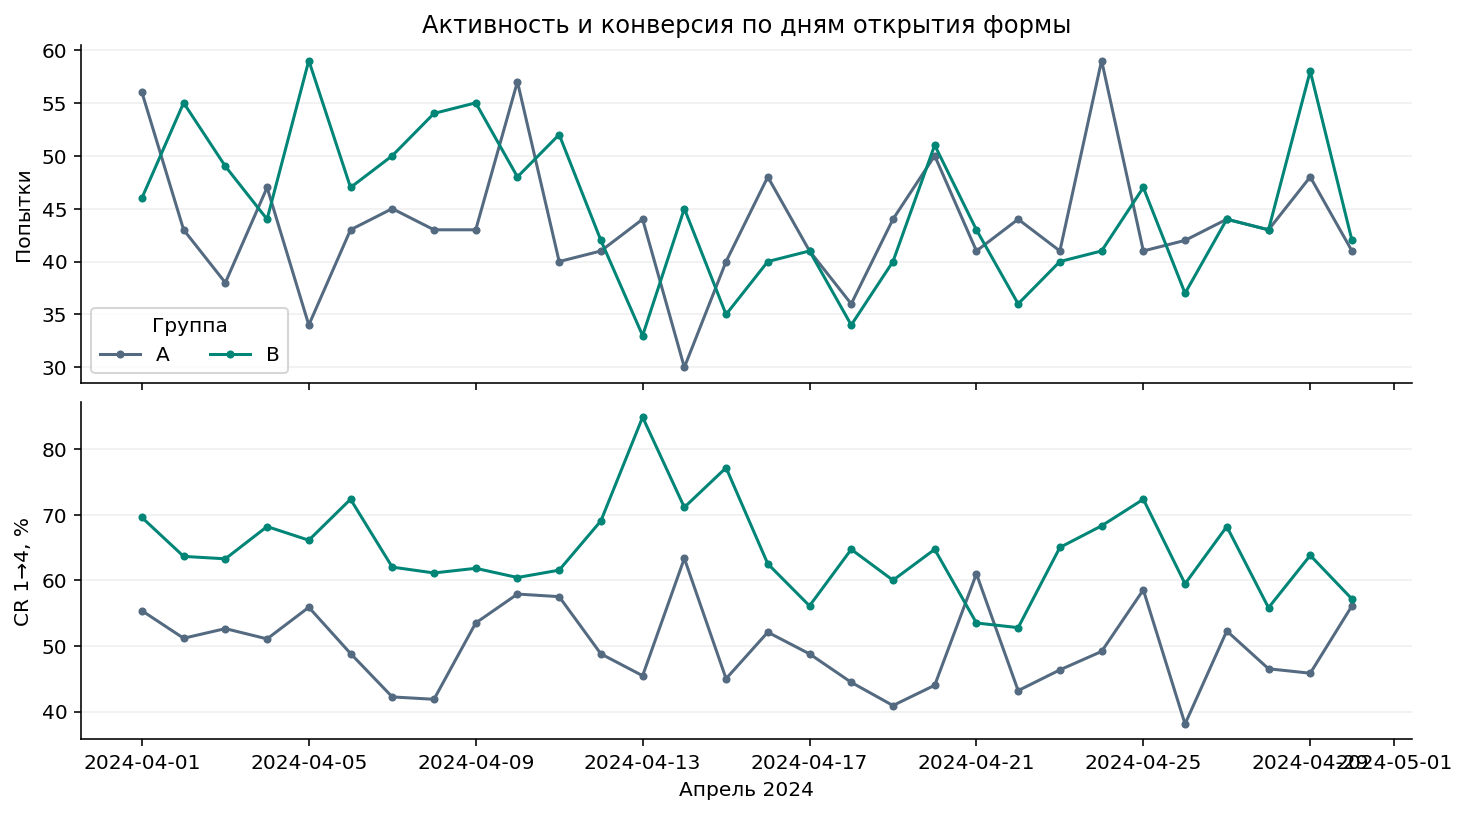

In [ ]:
assigned_counts = users.loc[users['group'].isin(['A', 'B']), 'group'].value_counts().reindex(['A', 'B'])
srm_p = stats.chisquare(assigned_counts.to_numpy()).pvalue
eda = clean.groupby('group').agg(users=('user_id', 'nunique'), attempts=('payment_id', 'size'),
                                 successes=('success', 'sum'))
eda['attempts_per_user'] = eda['attempts'] / eda['users']
eda['CR_attempt'] = eda['successes'] / eda['attempts']
print('Назначены в группы (до очистки):', assigned_counts.to_dict())
print(f'SRM при ожидаемом 50/50: p = {srm_p:.4f}')
print('\nОсновная выборка:\n', eda.round(4).to_string())
print('\nВозраст после обработки:\n', active_users.groupby('group')['age'].agg(['count', 'mean', 'median', 'min', 'max']).round(2).to_string())
balance = {}
for feature in ['device_type', 'city']:
    counts = pd.crosstab(active_users[feature], active_users['group']).reindex(columns=['A', 'B'])
    shares = counts.div(counts.sum(axis=0), axis=1) * 100
    # Редкую категорию пропущенного города показываем, но не включаем в χ².
    test_counts = counts.drop(index='Не указан', errors='ignore')
    chi_p = stats.chi2_contingency(test_counts, correction=False).pvalue
    balance[feature] = {'counts': counts, 'shares': shares, 'p': chi_p}
    print(f'\n{feature}, количества:\n{counts.to_string()}')
    print(f'{feature}, доли (%):\n{shares.round(2).to_string()}')
    print(f'Описательная проверка баланса χ²: p = {chi_p:.4f}')
print('\nРаспределение числа попыток на пользователя:\n', clean.groupby('user_id').size().value_counts().sort_index().to_string())

daily = clean.assign(day=clean['step1_opened'].dt.floor('D')).groupby(['day', 'group']).agg(
    attempts=('payment_id', 'size'), successes=('success', 'sum')).reset_index()
daily['cr'] = daily['successes'] / daily['attempts']
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, layout='constrained')
for g in ['A', 'B']:
    d = daily[daily['group'].eq(g)]
    axes[0].plot(d['day'], d['attempts'], marker='o', ms=3, color=COLORS[g], label=g)
    axes[1].plot(d['day'], 100*d['cr'], marker='o', ms=3, color=COLORS[g], label=g)
axes[0].set_ylabel('Попытки'); axes[0].set_title('Активность и конверсия по дням открытия формы')
axes[0].legend(title='Группа', ncols=2)
axes[1].set_ylabel('CR 1→4, %'); axes[1].set_xlabel('Апрель 2024')
for ax in axes: ax.grid(axis='y', alpha=.2)
plt.show()


## 3. Воронка и размер эффекта
Знаменатель CR 1→4 — все валидные попытки с открытием в период теста, включая незавершённые.
Для условных переходов используем число попыток, достигших непосредственно предыдущего шага.
Платёж может быть повторной попыткой того же пользователя; одна строка — одна попытка.


Воронка, количества попыток:
        step1_opened  step2_entered  step3_confirmed  step4_success
group                                                             
A              1307           1061              758            651
B              1351           1194              960            870

Воронка, % от открытия:
        step1_opened  step2_entered  step3_confirmed  step4_success
group                                                             
A             100.0          81.18            58.00          49.81
B             100.0          88.38            71.06          64.40

Условные переходы, %:
      1→2    2→3    3→4    1→4
A  81.18  71.44  85.88  49.81
B  88.38  80.40  90.62  64.40

Разница переходов B − A, п.п.:
 1→2     7.20
2→3     8.96
3→4     4.74
1→4    14.59

Основной эффект: +14.59 п.п.; относительный прирост +29.29%


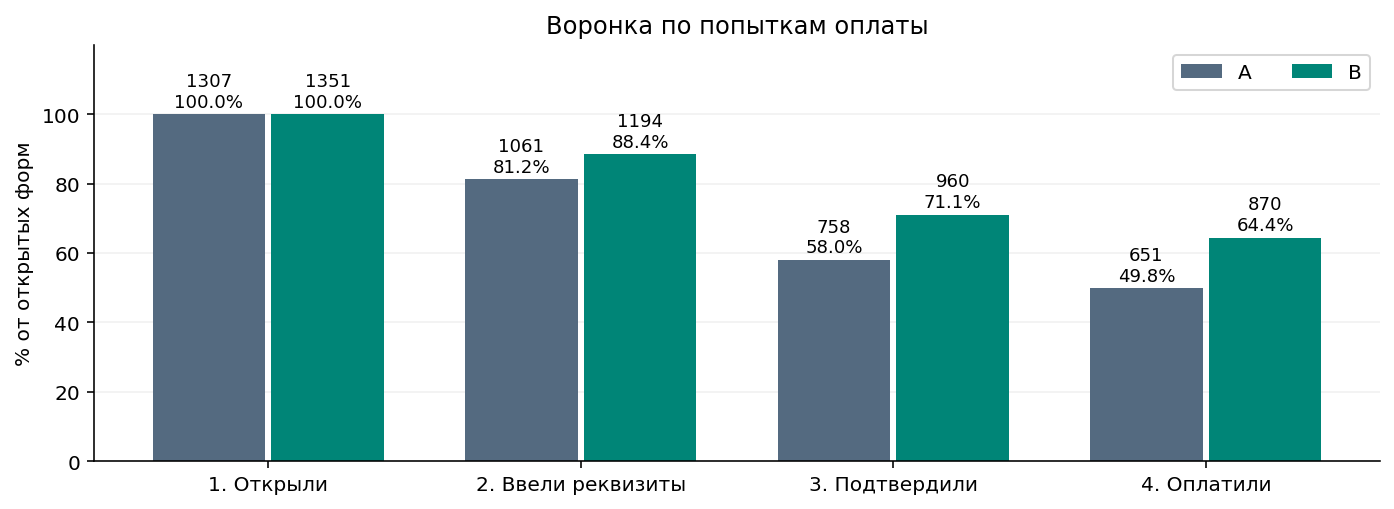

In [ ]:
funnel_counts = clean.groupby('group')[STEPS].count().reindex(['A', 'B'])
funnel_rates = funnel_counts.div(funnel_counts[STEPS[0]], axis=0)
transition_rates = pd.DataFrame(index=['A', 'B'])
for prev, nxt in zip(STEPS[:-1], STEPS[1:]):
    transition_rates[f'{STEPS.index(prev)+1}→{STEPS.index(nxt)+1}'] = funnel_counts[nxt] / funnel_counts[prev]
transition_rates['1→4'] = funnel_rates[STEPS[-1]]
effect = eda.loc['B', 'CR_attempt'] - eda.loc['A', 'CR_attempt']
relative_lift = effect / eda.loc['A', 'CR_attempt']
print('Воронка, количества попыток:\n', funnel_counts.to_string())
print('\nВоронка, % от открытия:\n', (100*funnel_rates).round(2).to_string())
print('\nУсловные переходы, %:\n', (100*transition_rates).round(2).to_string())
print('\nРазница переходов B − A, п.п.:\n', (100*(transition_rates.loc['B'] - transition_rates.loc['A'])).round(2).to_string())
print(f'\nОсновной эффект: {100*effect:+.2f} п.п.; относительный прирост {100*relative_lift:+.2f}%')

labels = ['1. Открыли', '2. Ввели реквизиты', '3. Подтвердили', '4. Оплатили']
fig, ax = plt.subplots(figsize=(9.5, 3.4), layout='constrained')
x = np.arange(4)
for offset, g in [(-.19, 'A'), (.19, 'B')]:
    bars = ax.bar(x+offset, 100*funnel_rates.loc[g], width=.36, label=g, color=COLORS[g])
    for rect, count, rate in zip(bars, funnel_counts.loc[g], funnel_rates.loc[g]):
        ax.text(rect.get_x()+rect.get_width()/2, rect.get_height()+1,
                f'{count}\n{100*rate:.1f}%', ha='center', va='bottom', fontsize=9)
ax.set_xticks(x, labels); ax.set_ylim(0, 120)
ax.set_yticks([0, 20, 40, 60, 80, 100]); ax.set_ylabel('% от открытых форм')
ax.set_title('Воронка по попыткам оплаты'); ax.legend(ncols=2)
ax.grid(axis='y', alpha=.18); ax.set_axisbelow(True)
plt.show()


## 4. Статистическая проверка основной метрики
**H₀:** CR_B − CR_A = 0. **H₁:** CR_B − CR_A ≠ 0. Двусторонняя проверка при α = 0,05.

Для пользователя i обозначим число попыток nᵢ, число успехов sᵢ. Групповая CR = Σsᵢ / Σnᵢ.
При n независимых пользователях в группе используем кластерную оценку дисперсии отношения сумм:

Var(CR) = [n / (n − 1)] · Σ(sᵢ − CR · nᵢ)² / (Σnᵢ)².

Стандартная ошибка разницы = √(Var_A + Var_B). Wald z = (CR_B − CR_A) / SE.
При примерно 750 независимых кластерах на группу используем нормальное приближение для двустороннего p-value.
Это учитывает зависимость попыток внутри человека; обычный z-тест по всем попыткам этого не делает.

Дополнительно строим percentile 95% ДИ разницы стратифицированным кластерным bootstrap:
50 000 раз выбираем пользователей с возвращением отдельно в A и B, сохраняя все их попытки, и пересчитываем отношение сумм.
Число bootstrap-повторов и seed фиксированы. Bootstrap-ДИ и асимптотический p-value — два приближённых способа оценки неопределённости.


CR A = 49.809%
CR B = 64.397%
Разница B − A = 14.588 п.п.
Кластерная SE = 1.891 п.п.
Wald 95% ДИ: [10.881; 18.295] п.п.
Bootstrap 95% ДИ: [10.912; 18.294] п.п.
Двусторонний кластерный Wald p-value = 1.222e-14
Bootstrap: независимая единица — пользователь; seed = 20241130 ; повторов = 50000
Точка — оценка эффекта; отрезок — 95%-й доверительный интервал; пунктир — нулевой эффект.
Интервал целиком правее нуля: данные поддерживают положительный эффект B по основной метрике.


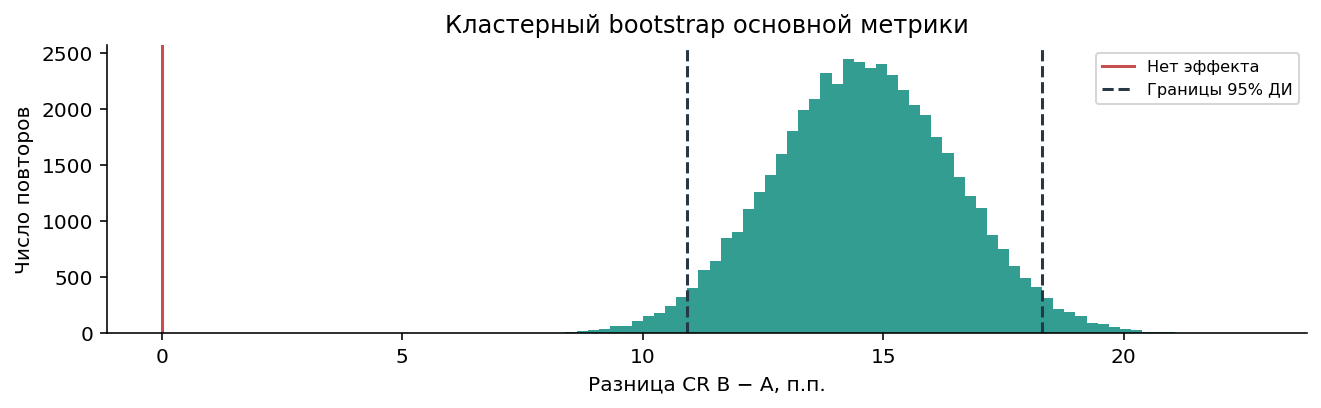

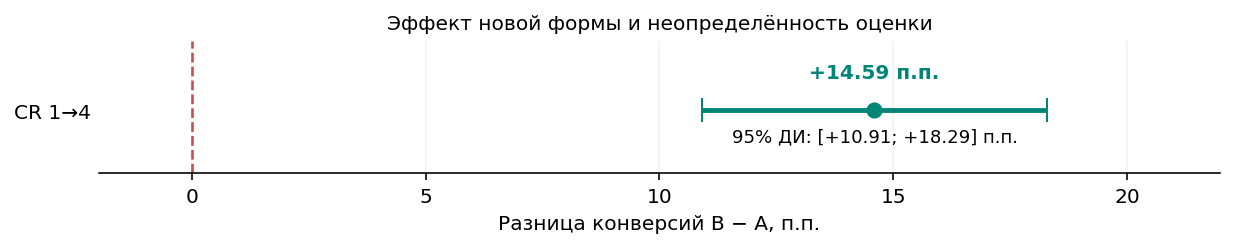

In [ ]:
def cluster_summary(frame):
    per_user = frame.groupby(['group', 'user_id']).agg(n=('success', 'size'), s=('success', 'sum')).reset_index()
    estimates = {}
    for g in ['A', 'B']:
        d = per_user[per_user['group'].eq(g)]
        p = d['s'].sum() / d['n'].sum()
        k = len(d)
        var = (k/(k-1)) * np.square(d['s'] - p*d['n']).sum() / d['n'].sum()**2
        estimates[g] = {'p': float(p), 'var': float(var), 'users': k}
    delta = estimates['B']['p'] - estimates['A']['p']
    se = np.sqrt(estimates['A']['var'] + estimates['B']['var'])
    pvalue = 2*stats.norm.sf(abs(delta/se))
    ci = np.array([delta-stats.norm.ppf(.975)*se, delta+stats.norm.ppf(.975)*se])
    return {'delta': float(delta), 'se': float(se), 'pvalue': float(pvalue), 'wald_ci': ci}, per_user

primary, per_user = cluster_summary(clean)
REPS, SEED = 50_000, 20241130
rng = np.random.default_rng(SEED)
boot_group = {}
for g in ['A', 'B']:
    vals = per_user.loc[per_user['group'].eq(g), ['n', 's']].to_numpy()
    estimates = np.empty(REPS)
    for start in range(0, REPS, 500):
        stop = min(start+500, REPS)
        sample = vals[rng.integers(0, len(vals), size=(stop-start, len(vals)))]
        totals = sample.sum(axis=1)
        estimates[start:stop] = totals[:, 1] / totals[:, 0]
    boot_group[g] = estimates
boot_delta = boot_group['B'] - boot_group['A']
boot_ci = np.quantile(boot_delta, [.025, .975])
print(f'CR A = {100*eda.loc["A", "CR_attempt"]:.3f}%')
print(f'CR B = {100*eda.loc["B", "CR_attempt"]:.3f}%')
print(f'Разница B − A = {100*primary["delta"]:.3f} п.п.')
print(f'Кластерная SE = {100*primary["se"]:.3f} п.п.')
print(f'Wald 95% ДИ: [{100*primary["wald_ci"][0]:.3f}; {100*primary["wald_ci"][1]:.3f}] п.п.')
print(f'Bootstrap 95% ДИ: [{100*boot_ci[0]:.3f}; {100*boot_ci[1]:.3f}] п.п.')
print(f'Двусторонний кластерный Wald p-value = {primary["pvalue"]:.3e}')
print('Bootstrap: независимая единица — пользователь; seed =', SEED, '; повторов =', REPS)

fig, ax = plt.subplots(figsize=(9, 2.7), layout='constrained')
ax.hist(100*boot_delta, bins=70, color=COLORS['B'], alpha=.8)
ax.axvline(0, color='#C64F50', lw=1.5, label='Нет эффекта')
for i, bound in enumerate(boot_ci):
    ax.axvline(100*bound, color='#263746', ls='--', label='Границы 95% ДИ' if i == 0 else None)
ax.set_xlabel('Разница CR B − A, п.п.'); ax.set_ylabel('Число повторов')
ax.set_title('Кластерный bootstrap основной метрики'); ax.legend(fontsize=8)
plt.show()

# График эффекта для отчёта: оценка и 95%-й кластерный bootstrap-интервал.
fig, ax = plt.subplots(figsize=(8.4, 1.6), layout='constrained')
delta_pp = 100*primary['delta']
ci_pp = 100*boot_ci
ax.errorbar(delta_pp, 0, xerr=np.array([[delta_pp-ci_pp[0]], [ci_pp[1]-delta_pp]]),
            fmt='o', color=COLORS['B'], markersize=7, capsize=6, elinewidth=2.4)
ax.axvline(0, color='#C64F50', ls='--', lw=1.3)
ax.text(delta_pp, .23, f'+{delta_pp:.2f} п.п.', ha='center', fontweight='bold', color=COLORS['B'])
ax.text(ci_pp.mean(), -.22, f'95% ДИ: [+{ci_pp[0]:.2f}; +{ci_pp[1]:.2f}] п.п.', ha='center', fontsize=9)
ax.set_yticks([0], ['CR 1→4']); ax.set_ylim(-.45, .5); ax.set_xlim(-2, 22)
ax.set_xticks([0, 5, 10, 15, 20]); ax.set_xlabel('Разница конверсий B − A, п.п.')
ax.set_title('Эффект новой формы и неопределённость оценки', fontsize=10)
ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
ax.grid(axis='x', alpha=.15); ax.set_axisbelow(True)
plt.show()
print('Точка — оценка эффекта; отрезок — 95%-й доверительный интервал; пунктир — нулевой эффект.')
print('Интервал целиком правее нуля: данные поддерживают положительный эффект B по основной метрике.')


## 5. Дополнительная пользовательская метрика
В знаменателе — уникальные пользователи с открытием формы. Успех = хотя бы одна успешная оплата за период.
После агрегации один пользователь даёт одно бинарное наблюдение, поэтому используем обычный z-тест двух долей с объединённой оценкой под H₀.
Для 95% ДИ разницы используем метод Newcombe на основе отдельных интервалов Wilson.
Это дополнительная проверка, а не вторая независимая возможность «найти значимость».


In [ ]:
user_result = clean.groupby(['group', 'user_id'])['success'].max().reset_index()
user_summary = user_result.groupby('group')['success'].agg(['size', 'sum', 'mean'])
n_a, n_b = user_summary.loc['A', 'size'], user_summary.loc['B', 'size']
s_a, s_b = user_summary.loc['A', 'sum'], user_summary.loc['B', 'sum']
p_a, p_b = s_a/n_a, s_b/n_b
pooled = (s_a+s_b)/(n_a+n_b)
user_z = (p_b-p_a)/np.sqrt(pooled*(1-pooled)*(1/n_a+1/n_b))
user_p = 2*stats.norm.sf(abs(user_z))

def wilson(s, n):
    z = stats.norm.ppf(.975)
    p = s/n
    center = (p+z*z/(2*n))/(1+z*z/n)
    half = z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/(1+z*z/n)
    return center-half, center+half

la, ua = wilson(s_a, n_a)
lb, ub = wilson(s_b, n_b)
user_delta = p_b-p_a
user_ci = np.array([user_delta-np.sqrt((p_b-lb)**2+(ua-p_a)**2),
                    user_delta+np.sqrt((ub-p_b)**2+(p_a-la)**2)])
print(user_summary.rename(columns={'size':'Пользователи', 'sum':'Успешные пользователи', 'mean':'Конверсия'}).round(4).to_string())
print(f'Разница = {100*user_delta:.2f} п.п.; 95% ДИ Newcombe [{100*user_ci[0]:.2f}; {100*user_ci[1]:.2f}] п.п.; p = {user_p:.3e}')


       Пользователи  Успешные пользователи  Конверсия
group                                                
A               750                    493     0.6573
B               750                    603     0.8040
Разница = 14.67 п.п.; 95% ДИ Newcombe [10.21; 19.05] п.п.; p = 1.530e-10


## 6. Сегменты и время заполнения
Разрезы по устройствам/городам — разведочные. Не делаем отдельных выводов о запуске по p-value сегментов и не заявляем доказанную неоднородность эффекта.
Время ввода реквизитов считаем только среди завершивших шаг 2; это условная метрика с возможным отбором, а не причинная оценка ускорения для всей аудитории.



device_type:
                    users  attempts  successes      cr
device_type group                                    
android     A        406       713        349  0.4895
            B        369       666        425  0.6381
ios         A        344       594        302  0.5084
            B        381       685        445  0.6496
Разница B − A, п.п.:
 device_type
android    14.87
ios        14.12

city:
                  users  attempts  successes      cr
city      group                                    
Москва    A        287       501        235  0.4691
          B        306       567        369  0.6508
Не указан A          1         1          1  1.0000
Регион    A        268       461        234  0.5076
          B        245       428        263  0.6145
СПб       A        194       344        181  0.5262
          B        199       356        238  0.6685
Разница B − A, п.п.:
 city
Москва       18.17
Не указан      NaN
Регион       10.69
СПб          14.24

Время до ввод

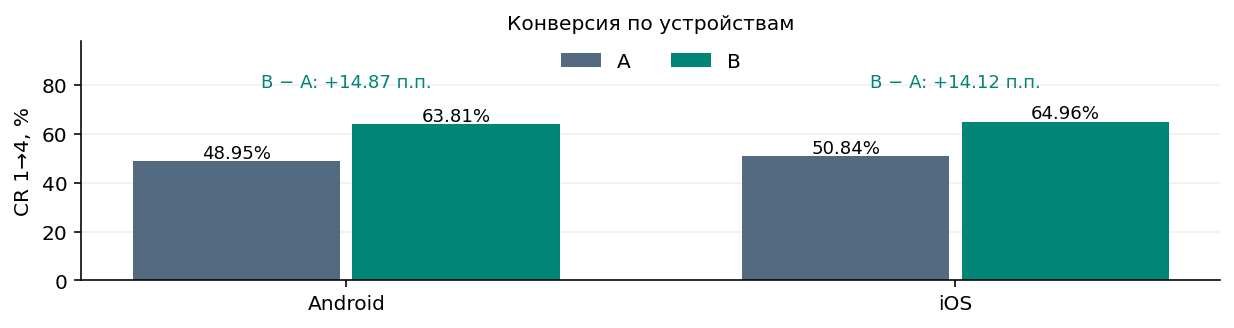

In [ ]:
segments = {}
for feature in ['device_type', 'city']:
    summary = clean.groupby([feature, 'group']).agg(users=('user_id', 'nunique'), attempts=('payment_id', 'size'),
                                                  successes=('success', 'sum'))
    summary['cr'] = summary['successes']/summary['attempts']
    segments[feature] = summary
    print(f'\n{feature}:\n', summary.round(4).to_string())
    rates = summary['cr'].unstack('group')
    print('Разница B − A, п.п.:\n', (100*(rates['B']-rates['A'])).round(2).to_string())
time_to_entry = (clean['step2_entered'] - clean['step1_opened']).dt.total_seconds()/60
time_summary = clean.assign(entry_minutes=time_to_entry).groupby('group')['entry_minutes'].agg(['count', 'median', 'mean', 'max'])
print('\nВремя до ввода реквизитов (минуты, только завершившие шаг 2):\n', time_summary.round(2).to_string())

fig, ax = plt.subplots(figsize=(8.4, 2.15), layout='constrained')
device_cr = segments['device_type']['cr'].unstack('group').reindex(['android', 'ios'])*100
x = np.arange(len(device_cr))
for g, offset in [('A', -.18), ('B', .18)]:
    bars = ax.bar(x+offset, device_cr[g], width=.34, color=COLORS[g], label=g)
    for rect, val in zip(bars, device_cr[g]):
        ax.text(rect.get_x()+rect.get_width()/2, val+1.2, f'{val:.2f}%', ha='center', fontsize=9)
for i, device in enumerate(device_cr.index):
    lift = device_cr.loc[device, 'B']-device_cr.loc[device, 'A']
    ax.text(i, 79, f'B − A: +{lift:.2f} п.п.', ha='center', fontsize=9, color=COLORS['B'])
ax.set_xticks(x, ['Android', 'iOS']); ax.set_ylabel('CR 1→4, %'); ax.set_ylim(0, 98)
ax.set_yticks([0, 20, 40, 60, 80])
ax.set_title('Конверсия по устройствам', fontsize=10)
ax.legend(ncols=2, loc='upper center', frameon=False, bbox_to_anchor=(.5, 1.03))
ax.grid(axis='y', alpha=.2); ax.set_axisbelow(True)
plt.show()
print('В обеих категориях устройств CR выше в B. Это описательный разрез, а не доказательство различия эффектов между устройствами.')


## 7. Устойчивость результата к обработке спорных записей
Основной вариант исключает конфликтного пользователя целиком. Дополнительно:
1. Убираем только строку с конфликтом (при допущении, что остальные события валидны).
2. Считаем лист пользователей источником правильной группы и исправляем группу спорного платежа.
3. Исключаем пользователей с некорректным возрастом или пропущенным городом.
4. Оставляем первую по времени попытку каждого пользователя (другой оцениваемый эффект).
Варианты 1 и 2 не устраняют неопределённость о фактически показанной форме; это проверки чувствительности, а не восстановленный факт.


In [ ]:
def prepared_variant(mask):
    d = merged.loc[mask].copy()
    d['group'] = d['user_group']
    d['success'] = d['step4_success'].notna().astype(int)
    return d

bad_profile_ids = users_raw.loc[bad_age | users_raw['city'].isna(), 'user_id']
variants = {
    'Основной: исключён конфликтный пользователь': clean,
    'Исключена только конфликтная строка': prepared_variant(basic_valid & ~mismatch),
    'Группа исправлена по листу пользователей': prepared_variant(basic_valid),
    'Также исключены некорректные профили': clean.loc[~clean['user_id'].isin(bad_profile_ids)],
    'Первая попытка каждого пользователя': clean.sort_values(['step1_opened', 'payment_id']).drop_duplicates('user_id'),
}
sensitivity_rows = []
for name, frame in variants.items():
    result, _ = cluster_summary(frame)
    sensitivity_rows.append([name, len(frame), frame.user_id.nunique(), 100*result['delta'],
                              100*result['wald_ci'][0], 100*result['wald_ci'][1], result['pvalue']])
sensitivity = pd.DataFrame(sensitivity_rows, columns=['Вариант', 'Попытки', 'Пользователи', 'Эффект, п.п.', 'ДИ от', 'ДИ до', 'p-value'])
print(sensitivity.to_string(index=False, float_format=lambda x:f'{x:.4f}', formatters={'p-value':lambda x:f'{x:.3e}'}))


                                    Вариант  Попытки  Пользователи  Эффект, п.п.   ДИ от   ДИ до   p-value
Основной: исключён конфликтный пользователь     2658          1500       14.5880 10.8814 18.2947 1.222e-14
        Исключена только конфликтная строка     2659          1501       14.6261 10.9202 18.3320 1.031e-14
   Группа исправлена по листу пользователей     2660          1501       14.5877 10.8840 18.2915 1.167e-14
       Также исключены некорректные профили     2657          1499       14.6265 10.9191 18.3338 1.054e-14
        Первая попытка каждого пользователя     1500          1500       14.9333  9.9966 19.8700 3.051e-09


## 8. Вывод и ограничения
Ниже вывод формируется из рассчитанных значений. Наблюдаемая разница в CR не означает, что для каждого человека вероятность оплаты выросла на столько же.
Причинная интерпретация требует корректной случайной раздачи версий, отсутствия смешения групп и сопоставимого сбора событий.


In [ ]:
print(f'Основная CR: A {100*eda.loc["A", "CR_attempt"]:.2f}% → B {100*eda.loc["B", "CR_attempt"]:.2f}%.')
print(f'Эффект {100*effect:+.2f} п.п. ({100*relative_lift:+.2f}% относительно A).')
print(f'95% bootstrap-ДИ [{100*boot_ci[0]:.2f}; {100*boot_ci[1]:.2f}] п.п.; кластерный p = {primary["pvalue"]:.6g}.')
if effect > 0 and primary['pvalue'] < .05 and boot_ci[0] > 0:
    print('Рекомендация: поддержать поэтапный запуск новой формы после проверки раздачи версий и технических ограничений.')
    print('Полное внедрение проводить с мониторингом конверсии и ошибок оплаты; оценку расходов на внедрение согласовать с командой.')
else:
    print('Рекомендация: имеющихся результатов недостаточно для уверенного запуска на всех; требуется разбор неопределённости/ухудшения.')
print('\nОграничения:')
print('• Соответствие A/старой и B/новой формы принято как допущение.')
print('• Есть конфликт группы одного пользователя; основной анализ исключает его, чувствительность показана отдельно.')
print('• Нет логов механизма рандомизации и экспозиции: причинная интерпретация условна.')
print('• Нет данных о комиссиях, суммах, возвратах, ошибках и затратах: финансовый эффект/безопасность внедрения не оценены.')
print('• Нет заранее заданного MDE, расчёта мощности и плана: значимость оценена ретроспективно; мощность постфактум не рассчитываем.')
print('• Наблюдения за один месяц; переносимость на будущие периоды и повторное использование не проверена.')
print('• Все события относятся к апрелю; неизвестно, дозревают ли поздние незавершённые попытки после окончания периода.')
print('• Сегменты и время заполнения — описательные результаты, отдельные причинные выводы не делаем.')


Основная CR: A 49.81% → B 64.40%.
Эффект +14.59 п.п. (+29.29% относительно A).
95% bootstrap-ДИ [10.91; 18.29] п.п.; кластерный p = 1.22235e-14.
Рекомендация: поддержать поэтапный запуск новой формы после проверки раздачи версий и технических ограничений.
Полное внедрение проводить с мониторингом конверсии и ошибок оплаты; оценку расходов на внедрение согласовать с командой.

Ограничения:
• Соответствие A/старой и B/новой формы принято как допущение.
• Есть конфликт группы одного пользователя; основной анализ исключает его, чувствительность показана отдельно.
• Нет логов механизма рандомизации и экспозиции: причинная интерпретация условна.
• Нет данных о комиссиях, суммах, возвратах, ошибках и затратах: финансовый эффект/безопасность внедрения не оценены.
• Нет заранее заданного MDE, расчёта мощности и плана: значимость оценена ретроспективно; мощность постфактум не рассчитываем.
• Наблюдения за один месяц; переносимость на будущие периоды и повторное использование не проверена.
• Все 